# EDA: списки пользователей AniList

Разведочный анализ данных, собранных краулером (`app/training/anilist_crawler.py`): 10 000 пользователей AniList, их списки аниме со статусами и оценками.

Цель — принять решения для модели рекомендаций:
1. **Качество данных**: что чистить перед обучением.
2. **Пользователи и тайтлы**: порог фильтра редких.
3. **Статусы**: веса взаимодействий.
4. **Оценки**: как переводить оценку в вес.
5. **Время**: честно ли деление на train/test по `updated_at`.
6. **Популярность**: насколько всё сосредоточено на хитах.

В конце каждого раздела — вывод и принятое решение.

In [1]:
import sys
from pathlib import Path

# ноутбук запускается из ml/notebooks, а пакет app лежит в ml/
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from app.training.datasets import DEFAULT_ANILIST_DIR

pd.set_option("display.float_format", "{:,.3f}".format)
COLOR = "#2a78d6"  # один цвет для одиночных рядов
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "axes.edgecolor": "#a3a29c",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

raw = pd.read_parquet(DEFAULT_ANILIST_DIR)
raw["updated_at"] = pd.to_datetime(raw["updated_at"], unit="s", utc=True)
print(f"{len(raw):,} записей, {raw.user_id.nunique():,} пользователей, {raw.anime_id.nunique():,} тайтлов")
raw.head()

4,124,979 записей, 9,986 пользователей, 21,493 тайтлов


,user_id,anime_id,status,score,progress,updated_at
0,8374932,177704,PAUSED,7,0,2026-10-26 18:13:49+00:00
1,8374932,1535,COMPLETED,8,37,2026-10-26 18:15:34+00:00
2,8374932,21507,CURRENT,8,11,2026-10-27 00:34:46+00:00
3,8374932,4224,REPEATING,9,9,2026-10-26 18:17:05+00:00
4,7462509,185660,COMPLETED,<NA>,12,2026-02-27 02:37:46+00:00


## 1. Качество данных

Проверяем то, что может испортить модель: дубли, значения вне допустимых границ, подозрительные даты, аномальных пользователей.

In [2]:
checks = pd.Series({
    "дубли (user_id, anime_id)": raw.duplicated(["user_id", "anime_id"]).sum(),
    "оценка вне 1–10": ((raw.score < 1) | (raw.score > 10)).sum(),
    "отрицательный progress": (raw.progress < 0).sum(),
    "updated_at пустой": raw.updated_at.isna().sum(),
    "updated_at раньше 2010": (raw.updated_at < "2010-01-01").sum(),
    "updated_at позже даты сбора": (raw.updated_at > "2026-10-29").sum(),
})
checks.to_frame("записей")

,записей
"дубли (user_id, anime_id)",0
оценка вне 1–10,0
отрицательный progress,0
updated_at пустой,711115
updated_at раньше 2010,0
updated_at позже даты сбора,0


In [3]:
print("Период:", raw.updated_at.min().date(), "—", raw.updated_at.max().date())
print(f"Без updated_at: {raw.updated_at.isna().mean():.1%} записей, у {raw[raw.updated_at.isna()].user_id.nunique():,} пользователей")
print(f"Без оценки: {raw.score.isna().mean():.1%}")
raw.status.value_counts().to_frame("записей").assign(доля=lambda t: t["записей"] / len(raw))

Период: 2010-03-22 — 2026-10-28
Без updated_at: 17.2% записей, у 2,281 пользователей
Без оценки: 60.6%


,записей,доля
status,,
COMPLETED,2506964,0.608
PLANNING,1071475,0.260
CURRENT,296580,0.072
DROPPED,152440,0.037
PAUSED,90206,0.022
REPEATING,7314,0.002


### Аномально большие списки

Смотрим на пользователей с самыми длинными списками: это могут быть «коллекционеры», которые отмечают всё подряд, а не реальные просмотры.

In [4]:
per_user = raw.groupby("user_id").size()
print(per_user.describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(0).to_string())

top = per_user.nlargest(5).index
(raw[raw.user_id.isin(top)]
 .pivot_table(index="user_id", columns="status", values="anime_id", aggfunc="size", fill_value=0)
 .assign(всего=lambda t: t.sum(axis=1))
 .sort_values("всего", ascending=False))

count   9,986.000
mean      413.000
std       558.000
min         1.000
50%       228.000
90%     1,032.000
99%     2,566.000
99.9%   5,160.000
max     9,846.000


status,COMPLETED,CURRENT,DROPPED,PAUSED,PLANNING,REPEATING,всего
user_id,,,,,,,
8226218,244,66,3263,2846,3235,192,9846
87384,3235,77,143,15,3213,4,6687
249619,2396,70,19,25,4160,0,6670
775468,5978,8,0,0,0,0,5986
5768839,327,20,1,78,5478,0,5904


### Массовые изменения списка

`updated_at` — время последнего изменения записи. Если у пользователя много записей с **одной и той же секундой**, это не просмотр, а массовая операция: импорт из MyAnimeList, массовое редактирование списка. Такие записи плохо говорят о том, *когда* человек смотрел тайтл.

In [5]:
# записи без updated_at в пачки не считаем: у них времени нет вовсе
batch = raw.groupby(["user_id", "updated_at"]).size().rename("batch_size")
raw = raw.join(batch, on=["user_id", "updated_at"])

sizes = [2, 10, 50, 500]
share = pd.Series({f">= {s}": (raw.batch_size >= s).mean() for s in sizes}, name="доля всех записей")
print(f"Пользователей с пачкой >= 50 записей: {batch[batch >= 50].reset_index().user_id.nunique():,}")
print(f"Самая большая пачка: {batch.max():,} записей с одним updated_at")
share.to_frame()

Пользователей с пачкой >= 50 записей: 859
Самая большая пачка: 5,390 записей с одним updated_at


,доля всех записей
>= 2,0.100
>= 10,0.096
>= 50,0.091
>= 500,0.046


### Записи без updated_at

У 17% записей AniList не отдаёт время изменения (видимо, старые записи). Смотрим, что с ними.

In [6]:
no_time = raw.updated_at.isna()
print(f"Оценка есть у {raw[no_time].score.notna().mean():.1%} записей без времени (у всех: {raw.score.notna().mean():.1%})")
raw[no_time].status.value_counts(normalize=True).to_frame("доля")

Оценка есть у 43.2% записей без времени (у всех: 39.4%)


,доля
status,
COMPLETED,0.649
PLANNING,0.219
CURRENT,0.059
DROPPED,0.044
PAUSED,0.029


Главный вопрос — сколько таких записей попадает в **тест** при делении по времени (последние 20% каждого пользователя): модель должна угадать «что человек посмотрит дальше», а не «что он импортировал одной кнопкой».

In [7]:
from app.training.datasets import filter_interactions, load_anilist
from app.training.evaluate import time_split

df = filter_interactions(load_anilist())
train, test = time_split(df)
test_batch = test.groupby(["user_id", "updated_at"])["anime_id"].transform("size")
print(f"После фильтра: {len(df):,} записей, тест: {len(test):,}")
pd.Series({
    "без updated_at (train)": train.updated_at.isna().mean(),
    "без updated_at (test)": test.updated_at.isna().mean(),
    "в пачках >= 10 (test)": (test_batch >= 10).mean(),
    "в пачках >= 50 (test)": (test_batch >= 50).mean(),
}, name="доля").to_frame()

После фильтра: 4,111,954 записей, тест: 818,534


,доля
без updated_at (train),0.209
без updated_at (test),0.027
в пачках >= 10 (test),0.047
в пачках >= 50 (test),0.038


### Вывод по разделу 1

- **Значения корректны**: дублей нет, оценки в 1–10, даты в пределах 2010 — дата сбора. Чистить ничего не нужно.
- **У 17% записей нет `updated_at`** (по статусам и оценкам обычные записи, видимо старые). Раньше `time_split` ставил их в конец и они уходили в тест (33% теста). **Решение:** записи без времени считаются самыми ранними и всегда остаются в train (исправлено в `evaluate.py`).
- **Массовые изменения** (пачки от 50 записей с одной секундой, импорт или массовая правка): 9% записей, но в тесте только ~3%. **Решение:** оставить как есть, это небольшой шум.
- **«Коллекционеры»** с тысячами записей (например, 9846 тайтлов, из них 244 просмотренных) есть, но их мало: у 99% пользователей до 2566 записей. **Решение:** пока не удалять, вернуться к этому в разделе 2.

## 2. Пользователи и тайтлы

Сколько тайтлов у типичного пользователя и у скольких пользователей есть типичный тайтл. От этого зависит порог `filter_interactions`: модель не может выучить вкус пользователя по 2 записям и «характер» тайтла, который есть у 3 человек. Сейчас порог 5/5 (у пользователя ≥ 5 тайтлов, у тайтла ≥ 5 пользователей).

Здесь данные **до фильтра**, статусы уже в нашем формате.

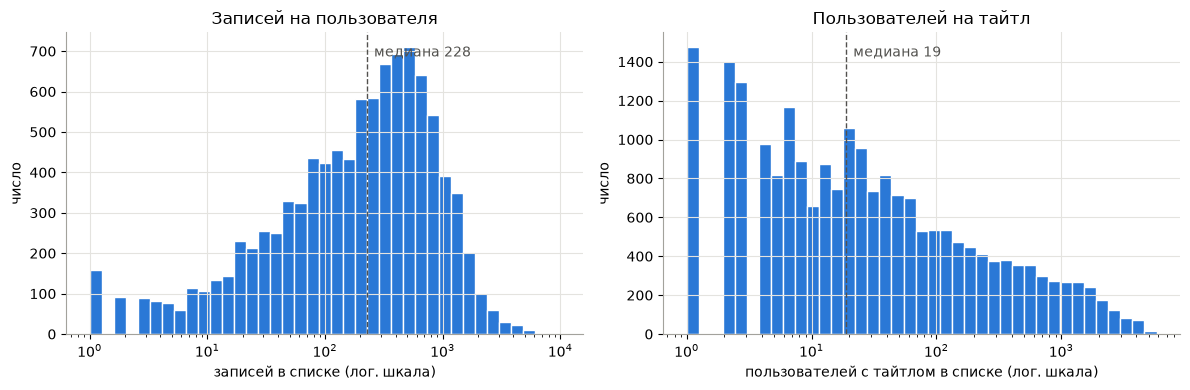

,пользователи,тайтлы
count,"9,986.000","21,493.000"
mean,413.000,192.000
std,558.000,516.000
min,1.000,1.000
10%,16.000,2.000
50%,228.000,19.000
90%,"1,032.000",509.000
99%,"2,566.000","2,735.000"
max,"9,846.000","5,793.000"


In [8]:
inter = load_anilist()
per_user = inter.groupby("user_id").size()
per_item = inter.groupby("anime_id").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, counts, title, xlabel in [
    (axes[0], per_user, "Записей на пользователя", "записей в списке"),
    (axes[1], per_item, "Пользователей на тайтл", "пользователей с тайтлом в списке"),
]:
    bins = np.logspace(0, np.log10(counts.max()), 40)
    ax.hist(counts, bins=bins, color=COLOR, edgecolor="white", linewidth=1)
    ax.set_xscale("log")
    ax.axvline(counts.median(), color="#52514e", linestyle="--", linewidth=1)
    ax.annotate(f"медиана {counts.median():.0f}", (counts.median(), ax.get_ylim()[1] * 0.92),
                xytext=(5, 0), textcoords="offset points", color="#52514e")
    ax.set(title=title, xlabel=xlabel + " (лог. шкала)", ylabel="число")
plt.tight_layout()
plt.show()

pd.DataFrame({"пользователи": per_user.describe(percentiles=[0.1, 0.5, 0.9, 0.99]),
              "тайтлы": per_item.describe(percentiles=[0.1, 0.5, 0.9, 0.99])}).round(0)

### Длинный хвост тайтлов

Многие тайтлы есть у единиц. Сколько их и какую долю записей они дают?

In [9]:
thresholds = [1, 5, 10, 20, 50]
pd.DataFrame({
    "тайтлов": [(per_item >= t).sum() for t in thresholds],
    "доля тайтлов": [(per_item >= t).mean() for t in thresholds],
    "доля записей": [per_item[per_item >= t].sum() / len(inter) for t in thresholds],
}, index=[f">= {t} польз." for t in thresholds])

,тайтлов,доля тайтлов,доля записей
>= 1 польз.,21493,1.000,1.000
>= 5 польз.,16336,0.760,0.997
>= 10 польз.,13462,0.626,0.992
>= 20 польз.,10718,0.499,0.983
>= 50 польз.,7206,0.335,0.956


### Порог фильтра

Сравниваем пороги: сколько остаётся записей, пользователей, тайтлов и какая получается **плотность** (доля заполненных клеток матрицы «пользователь × тайтл»). Для сравнения: в классическом датасете MovieLens-1M плотность около 4,5%.

In [10]:
rows = {}
for min_user, min_item in [(5, 5), (5, 10), (5, 20), (20, 20), (5, 50)]:
    f = filter_interactions(inter, min_user, min_item)
    n_users, n_items = f.user_id.nunique(), f.anime_id.nunique()
    rows[f"{min_user}/{min_item}"] = {"записей": len(f), "пользователей": n_users,
                                      "тайтлов": n_items, "плотность": len(f) / n_users / n_items}
pd.DataFrame(rows).T.astype({"записей": int, "пользователей": int, "тайтлов": int})

,записей,пользователей,тайтлов,плотность
5/5,4111954,9566,16335,0.026
5/10,4092783,9566,13462,0.032
5/20,4054033,9564,10717,0.040
20/20,4045274,8802,10714,0.043
5/50,3943470,9559,7205,0.057


### «Коллекционеры»

Пользователи с огромными списками дают непропорционально много записей. Если их списки устроены иначе, чем у остальных (например, почти всё в «планах»), они могут перекосить модель.

In [11]:
by_size = per_user.sort_values(ascending=False)
share = by_size.cumsum() / by_size.sum()
print(f"Топ-1% пользователей дают {share.iloc[len(by_size) // 100]:.1%} записей, топ-10% — {share.iloc[len(by_size) // 10]:.1%}")
print("Пользователей с > 2000 / 3000 / 5000 записей:", *[(per_user > t).sum() for t in [2000, 3000, 5000]])

group = np.where(inter.user_id.map(per_user) > 3000, "> 3000 записей", "остальные")
pd.crosstab(inter.status, group, normalize="columns", colnames=["пользователи"])

Топ-1% пользователей дают 8.9% записей, топ-10% — 40.8%
Пользователей с > 2000 / 3000 / 5000 записей: 194 64 12


пользователи,> 3000 записей,остальные
status,,
completed,0.582,0.611
dropped,0.040,0.037
on_hold,0.031,0.021
planned,0.325,0.255
watching,0.022,0.075


### Вывод по разделу 2

- **Пользователи**: медиана 228 записей, у 90% до ~1000. Меньше 5 записей у 420 человек, их убирает фильтр (им достанутся рекомендации холодного старта).
- **Тайтлы — длинный хвост**: половина тайтлов есть меньше чем у 20 пользователей, но даёт меньше 2% записей.
- **Порог**: при 5/5 остаётся 16,3 тыс. тайтлов, плотность 2,6% — достаточно для ALS. При 5/20 тайтлов 10,7 тыс., плотность 4%. **Решение:** оставить 5/5, а 5/20 сравнить при обучении ALS по NDCG@10 на одном и том же тесте: это вопрос эксперимента.
- **«Коллекционеры»**: топ-1% пользователей дают 9% записей, но состав списков почти как у остальных (чуть больше «в планах»). **Решение:** не удалять и не ограничивать; лишние «планы» учитываются весами статусов (раздел 3).

## 3. Статусы

Для ALS каждая запись «пользователь — тайтл» превращается в число — **вес**: насколько это взаимодействие говорит «тайтл пользователю интересен». Статус — главный источник этого сигнала (оценка есть только у 39% записей).

Смотрим, как статус связан с оценкой: если брошенным тайтлам ставят низкие оценки, `dropped` — сигнал «не понравилось», а не «интересно».

In [12]:
by_status = inter.groupby("status")
# оценка относительно личного среднего: у «доброго» пользователя 7 — это мало
personal = inter.score - inter.groupby("user_id").score.transform("mean")

status_table = pd.DataFrame({
    "доля записей": by_status.size() / len(inter),
    "с оценкой": by_status.score.apply(lambda s: s.notna().mean()),
    "средняя оценка": by_status.score.mean(),
    "оценка >= 7": by_status.score.apply(lambda s: (s.dropna() >= 7).mean()),
    "оценка <= 4": by_status.score.apply(lambda s: (s.dropna() <= 4).mean()),
    "отн. личного среднего": personal.groupby(inter.status).mean(),
}).sort_values("доля записей", ascending=False)
status_table

,доля записей,с оценкой,средняя оценка,оценка >= 7,оценка <= 4,отн. личного среднего
status,,,,,,
completed,0.610,0.614,7.424,0.762,0.050,0.066
planned,0.260,0.004,7.579,0.766,0.119,-0.150
watching,0.072,0.071,7.833,0.825,0.036,-0.001
dropped,0.037,0.275,4.574,0.127,0.445,-2.334
on_hold,0.022,0.134,7.096,0.691,0.048,-0.340


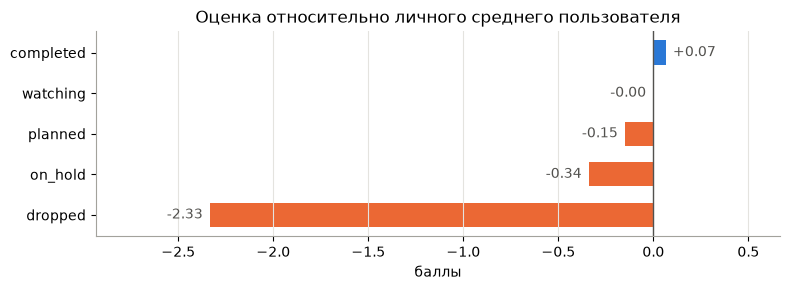

In [13]:
dev = status_table["отн. личного среднего"].astype(float).sort_values()
fig, ax = plt.subplots(figsize=(8, 3))
colors = np.where(dev < 0, "#eb6834", COLOR)  # ниже личного среднего / выше
ax.barh(dev.index, dev.values, color=colors, height=0.6)
ax.axvline(0, color="#52514e", linewidth=1)
for y, v in enumerate(dev.values):
    ax.annotate(f"{v:+.2f}", (v, y), xytext=(5 if v >= 0 else -5, 0), textcoords="offset points",
                ha="left" if v >= 0 else "right", va="center", color="#52514e")
ax.set(title="Оценка относительно личного среднего пользователя", xlabel="баллы")
ax.set_xlim(dev.min() - 0.6, max(dev.max(), 0) + 0.6)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### «В планах»

У `planned` почти нет оценок (пользователь ещё не смотрел), поэтому по оценкам его не понять. Смотрим, какие тайтлы люди откладывают: такие же популярные, как просмотренные, или более редкие.

In [14]:
completed_count = inter[inter.status == "completed"].groupby("anime_id").size()
popularity = inter.anime_id.map(completed_count).fillna(0)
print(f"planned есть у {inter[inter.status == 'planned'].user_id.nunique() / inter.user_id.nunique():.0%} пользователей, "
      f"dropped — у {inter[inter.status == 'dropped'].user_id.nunique() / inter.user_id.nunique():.0%}")
popularity.groupby(inter.status).median().rename("медиана: сколько человек досмотрели тайтл").to_frame()

planned есть у 84% пользователей, dropped — у 55%


,медиана: сколько человек досмотрели тайтл
status,
completed,930.000
dropped,589.000
on_hold,625.000
planned,382.000
watching,606.000


### Вывод по разделу 3

- **completed** (61%) и **watching** (7%) — явный сигнал «нравится»: оценки на уровне личного среднего, у «смотрю» средняя даже выше (7,8).
- **on_hold** (2%) — слабый плюс: оценки на 0,3 балла ниже личного среднего.
- **planned** (26%) — интерес без проверки: оценок почти нет (0,4%). Откладывают более редкие тайтлы (медиана 382 досмотревших против 930 у просмотренных) — полезно, чтобы советовать не только хиты.
- **dropped** (3,7%) — сигнал «не понравилось»: на 2,3 балла ниже личного среднего, 45% оценок 1–4.

**Решение — стартовые веса статусов:** completed 1,0 · watching 1,0 · on_hold 0,5 · planned 0,5 · dropped 0. ALS (`implicit`) понимает только силу интереса, отрицательный вес ему не подходит, поэтому брошенное **не участвует в обучении, но исключается из рекомендаций** (пользователь его уже пробовал). Варианты (например, planned 0,3 / 0,5 / 1,0) сравним на ALS по NDCG@10.

## 4. Оценки

Оценка уточняет вес статуса: просмотренное на 10 — сильнее, чем просмотренное на 6. Но сравнивать оценки разных людей напрямую нельзя: у одного все тайтлы на 8–10, у другого 7 — уже высокая оценка.

Краулер запрашивает оценки в формате `POINT_10`: AniList сам переводит в 10-балльную шкалу, даже если пользователь ставит звёзды (1–5) или 100-балльные.

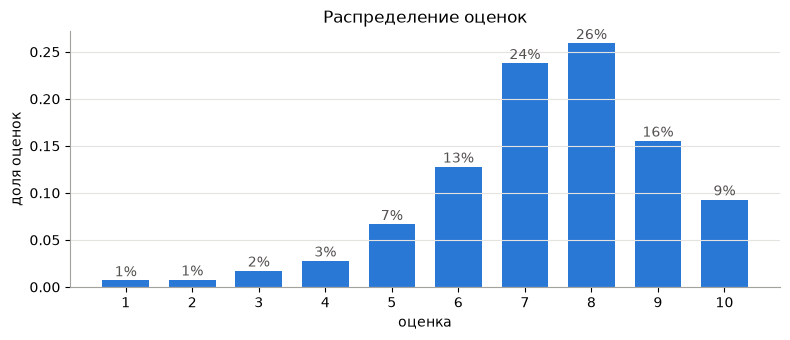

Средняя оценка 7.35, оценок 7–10: 75%


In [15]:
scored = inter[inter.score.notna()]
dist = scored.score.value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(dist.index.astype(int), dist.values, color=COLOR, width=0.7)
for x, v in zip(dist.index.astype(int), dist.values):
    ax.annotate(f"{v:.0%}", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", color="#52514e")
ax.set(title="Распределение оценок", xlabel="оценка", ylabel="доля оценок", xticks=range(1, 11))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
print(f"Средняя оценка {scored.score.mean():.2f}, оценок 7–10: {(scored.score >= 7).mean():.0%}")

### Кто ставит оценки

Оценки есть у 39% записей. Это «все понемногу» или одни ставят всем, а другие никому?

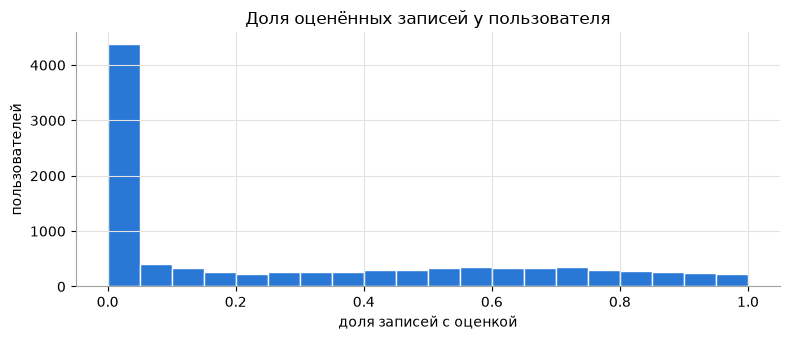

Без единой оценки: 32% пользователей, оценивают >= 90% списка: 5%


In [16]:
rated_share = inter.score.notna().groupby(inter.user_id).mean()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(rated_share, bins=20, range=(0, 1), color=COLOR, edgecolor="white", linewidth=1)
ax.set(title="Доля оценённых записей у пользователя", xlabel="доля записей с оценкой", ylabel="пользователей")
plt.tight_layout()
plt.show()
print(f"Без единой оценки: {(rated_share == 0).mean():.0%} пользователей, оценивают >= 90% списка: {(rated_share >= 0.9).mean():.0%}")

### Личная шкала

Для пользователей с ≥ 10 оценками смотрим личное среднее и разброс. Если средние сильно различаются, оценку нужно сравнивать с личным средним, а не с общим.

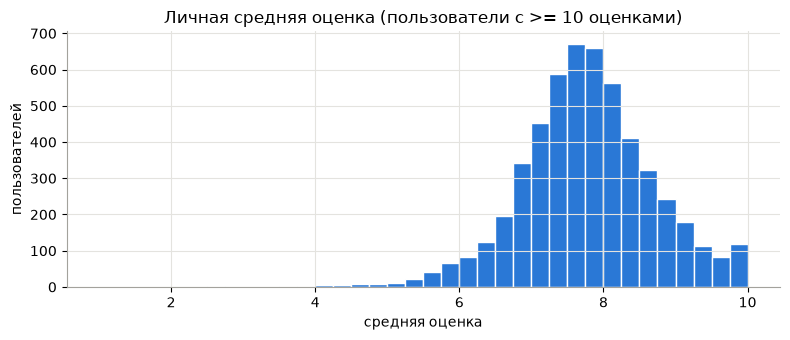

Пользователей с >= 10 оценками: 5,330
Ставят одну и ту же оценку всем: 75, только чётные (похоже на 5 звёзд): 152


,оценок,среднее,разброс (std)
count,"5,330.000","5,330.000","5,330.000"
mean,303.760,7.770,1.360
std,393.340,0.930,0.500
min,10.000,1.000,0.000
10%,23.000,6.710,0.810
50%,173.000,7.760,1.320
90%,723.100,8.940,1.980
max,"5,951.000",10.000,4.650


In [17]:
per_user_scores = scored.groupby("user_id").score
scale = pd.DataFrame({"оценок": per_user_scores.size(), "среднее": per_user_scores.mean(),
                      "разброс (std)": per_user_scores.std()}).astype(float)
scale = scale[scale["оценок"] >= 10]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(scale["среднее"], bins=np.arange(1, 10.25, 0.25), color=COLOR, edgecolor="white", linewidth=1)
ax.set(title="Личная средняя оценка (пользователи с >= 10 оценками)", xlabel="средняя оценка", ylabel="пользователей")
plt.tight_layout()
plt.show()

values = scored.groupby("user_id").score.apply(lambda s: set(s.astype(int)))
values = values[scale.index]
print(f"Пользователей с >= 10 оценками: {len(scale):,}")
print(f"Ставят одну и ту же оценку всем: {(scale['разброс (std)'] == 0).sum()}, "
      f"только чётные (похоже на 5 звёзд): {values.apply(lambda v: v <= {2, 4, 6, 8, 10}).sum()}")
scale.describe(percentiles=[0.1, 0.5, 0.9]).round(2)

### Вывод по разделу 4

- Оценки смещены вверх: средняя 7,35, **75% оценок — 7–10**, оценки 1–4 только у 7% (не понравившееся чаще бросают, чем оценивают).
- **32% пользователей не ставят оценок вовсе**, для них работает только вес статуса. Почти всё оценивают лишь 5%.
- **Личная шкала различается**: личное среднее от 6,7 до 8,9 (10–90%), типичный разброс ±1,3 балла. Оценку нужно сравнивать с личным средним, а не с общим.
- 75 человек ставят всем одну оценку, 152 — только чётные (звёзды, переведённые AniList в 10-балльную шкалу); отдельной обработки не требуется.

**Решение: вес = вес статуса × поправка за оценку.**
- нет оценки → поправка 1;
- оценка 1–4 → вес 0 (как брошенное: не в обучении и не в рекомендациях; согласуется с `relevant_items`);
- оценка 5–10 → поправка `1 + 0,2 × (оценка − личное среднее)`, ограничена [0,5; 1,5]. При < 5 оценках у пользователя вместо личного среднего берётся общее (7,35).

Коэффициент 0,2 — стартовый; на ALS сравним с 0 (без оценок) и 0,4.

## 5. Время

Проверка модели устроена так: прячем «будущее» и смотрим, угадает ли модель. Сейчас (`time_split`) будущее у каждого пользователя своё — последние 20% его записей. Минус: у одного пользователя «будущее» — 2023 год, а модель учится на записях других людей за 2026-й, то есть **видит будущее** (например, какие тайтлы станут популярны).

Честнее **одна общая дата отсечения** для всех: всё до неё — обучение, после — тест. Так модель работает и в реальности: обучили сегодня, рекомендуем на следующий месяц. Раньше мы опасались, что после общей даты у многих не будет записей. Проверяем.

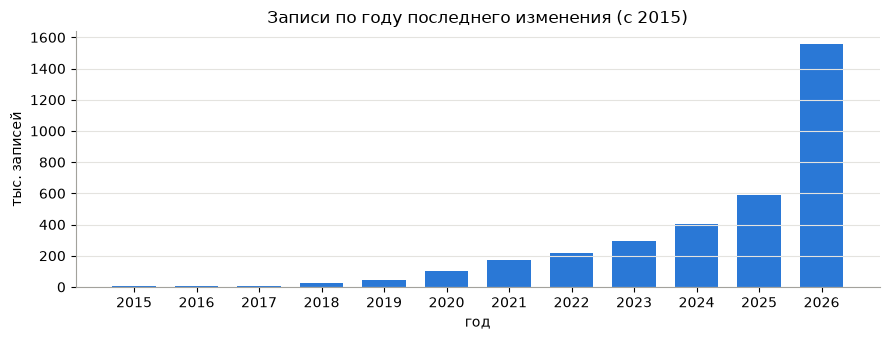

Последняя запись: 2026-10-28
За последние 30 дней: 12%, за 90 дней: 23%


In [18]:
dated = inter.updated_at.dropna()
by_year = dated.dt.year.value_counts().sort_index()
by_year = by_year[by_year.index >= 2015]

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_year.index, by_year.values / 1e3, color=COLOR, width=0.7)
ax.set(title="Записи по году последнего изменения (с 2015)", xlabel="год", ylabel="тыс. записей", xticks=by_year.index)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

last = dated.max()
print(f"Последняя запись: {last.date()}")
print(f"За последние 30 дней: {(dated >= last - pd.Timedelta(days=30)).mean():.0%}, за 90 дней: {(dated >= last - pd.Timedelta(days=90)).mean():.0%}")

Краулер брал пользователей из **свежей ленты активностей** AniList, поэтому почти у всех есть недавние записи. Сравниваем общие даты отсечения: сколько пользователей попадёт в проверку (нужно ≥ 5 записей до даты и хотя бы одна после) и сколько записей окажется в тесте.

In [19]:
rows = {}
for days in [28, 60, 120]:
    cutoff = last - pd.Timedelta(days=days)
    after = df.updated_at >= cutoff  # df — после filter_interactions (раздел 1)
    before_counts = df[~after].groupby("user_id").size()
    users = set(df[after].user_id) & set(before_counts[before_counts >= 5].index)
    rows[f"{days} дней ({cutoff.date()})"] = {
        "пользователей в проверке": len(users),
        "доля пользователей": len(users) / df.user_id.nunique(),
        "тестовых записей": int(df[after].user_id.isin(users).sum()),
    }
pd.DataFrame(rows).T

,пользователей в проверке,доля пользователей,тестовых записей
28 дней (2026-09-30),"8,562.000",0.895,"282,507.000"
60 дней (2026-08-29),"8,055.000",0.842,"434,481.000"
120 дней (2026-06-30),"6,995.000",0.731,"584,348.000"


### Насколько «подглядывание в будущее» завышает оценку

Грубый baseline «самое популярное, кроме уже виденного» при двух схемах деления. Если при личном делении он заметно лучше, значит модель там подглядывает (популярность считается в том числе по будущим записям других людей).

In [20]:
from app.training.evaluate import evaluate, relevant_items


def popular_baseline(train, test, k=10):
    relevant = relevant_items(test)
    top = train.anime_id.value_counts().index[:500]
    seen = train.groupby("user_id").anime_id.agg(set)
    recs = {u: [a for a in top if a not in seen.get(u, set())][:k] for u in relevant}
    return evaluate(recs, relevant, k)


cutoff = last - pd.Timedelta(days=28)
after = df.updated_at >= cutoff
before_counts = df[~after].groupby("user_id").size()
global_train = df[~after]
global_test = df[after & df.user_id.isin(before_counts[before_counts >= 5].index)]
pd.DataFrame({
    "личное (последние 20%)": popular_baseline(train, test),
    "общая дата (28 дней)": popular_baseline(global_train, global_test),
}).T.round(3)

,precision@10,recall@10,ndcg@10,users
личное (последние 20%),0.170,0.027,0.184,"9,564.000"
общая дата (28 дней),0.070,0.029,0.080,"8,561.000"


Но precision и NDCG зависят ещё и от того, **сколько** тайтлов спрятано у пользователя: чем их больше, тем легче попасть. Сравниваем состав теста при двух схемах.

In [21]:
def test_profile(test):
    relevant = pd.Series({u: len(items) for u, items in relevant_items(test).items()})
    batch = test.groupby(["user_id", "updated_at"]).anime_id.transform("size")
    return {
        "релевантных на польз. (медиана)": relevant.median(),
        "польз. с < 10 релевантными": (relevant < 10).mean(),
        "в пачках >= 50": (batch >= 50).mean(),
        **{f"доля {s}": v for s, v in test.status.value_counts(normalize=True).items()},
    }


pd.DataFrame({"личное (последние 20%)": test_profile(test),
              "общая дата (28 дней)": test_profile(global_test)}).round(3)

,личное (последние 20%),общая дата (28 дней)
релевантных на польз. (медиана),47.000,16.000
польз. с < 10 релевантными,0.185,0.305
в пачках >= 50,0.038,0.101
доля completed,0.507,0.396
доля planned,0.273,0.252
доля watching,0.156,0.291
доля dropped,0.040,0.034
доля on_hold,0.024,0.027


### Вывод по разделу 5

- Данные свежие: 38% записей изменены в 2026 году, 12% — за последний месяц. Краулер брал пользователей из свежей ленты активностей, поэтому почти все они активны сейчас.
- Опасение, что при общей дате отсечения у многих не будет записей «после», **не подтвердилось**: при отсечении 28 дней назад в проверке 90% пользователей и 283 тыс. тестовых записей.
- Сравнить схемы по NDCG baseline нельзя: при общей дате у пользователя спрятано втрое меньше релевантных тайтлов (медиана 16 против 47), а от этого зависят precision и NDCG; recall почти одинаковый. **Цифры разных схем между собой не сравниваются — сравниваются модели внутри одной схемы.**
- Минусы общей даты: 10% теста — массовые импорты (против 4%), у 30% пользователей меньше 10 релевантных тайтлов, в тесте больше «смотрю» (29%).

**Решение:** основная проверка — **общая дата отсечения, последние 28 дней** (модель не видит будущего, как в реальной работе: обучили сегодня — проверяем на следующих 4 неделях). В `evaluate.py` добавить `cutoff_split` с unit-тестами. `time_split` (последние 20% у каждого) остаётся второй проверкой: вывод «модель A лучше B» надёжен, если он верен в обеих схемах.

## 6. Популярность

Baseline «самое популярное» — главный соперник ALS. Смотрим:
1. насколько записи сосредоточены на хитах;
2. какие тайтлы спрятаны в тесте — всегдашние хиты или что-то другое;
3. какой baseline честно сравнивать с ALS и нужно ли бороться с перекосом в популярное.

Данные после фильтра (`df`), проверка — общая дата отсечения 28 дней (раздел 5).

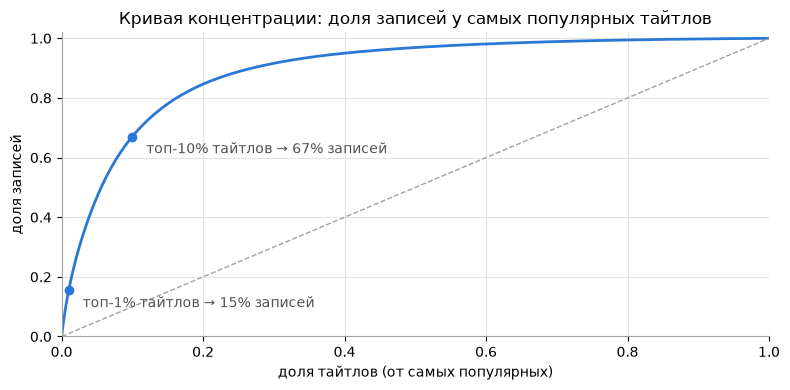

Самый популярный тайтл есть у 60% пользователей


,топ-1%,топ-10%,топ-50%,Джини
все записи,0.154,0.671,0.969,0.787
completed + watching,0.188,0.721,0.975,0.816


In [22]:
counts = df.anime_id.value_counts()
curve = counts.cumsum().values / counts.sum()
x = np.arange(1, len(counts) + 1) / len(counts)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, curve, color=COLOR, linewidth=2)
ax.plot([0, 1], [0, 1], color="#a3a29c", linestyle="--", linewidth=1)  # если бы все тайтлы были одинаково популярны
for p in [0.01, 0.10]:
    y = curve[int(len(counts) * p) - 1]
    ax.scatter([p], [y], color=COLOR, zorder=3)
    ax.annotate(f"топ-{p:.0%} тайтлов → {y:.0%} записей", (p, y), xytext=(10, -12), textcoords="offset points", color="#52514e")
ax.set(title="Кривая концентрации: доля записей у самых популярных тайтлов",
       xlabel="доля тайтлов (от самых популярных)", ylabel="доля записей", xlim=(0, 1), ylim=(0, 1.02))
plt.tight_layout()
plt.show()


def gini(c):
    v = np.sort(c.values)
    return 1 - 2 * np.sum(np.cumsum(v) / v.sum()) / len(v) + 1 / len(v)


positive = df[df.status.isin(["completed", "watching"])].anime_id.value_counts()
rows = {}
for name, c in [("все записи", counts), ("completed + watching", positive)]:
    share = c.cumsum() / c.sum()
    rows[name] = {**{f"топ-{p}%": share.iloc[int(len(c) * p / 100) - 1] for p in [1, 10, 50]},
                  "Джини": gini(c)}
print(f"Самый популярный тайтл есть у {counts.iloc[0] / df.user_id.nunique():.0%} пользователей")
pd.DataFrame(rows).T

### Что спрятано в тесте

Если в тесте в основном всегдашние хиты, baseline «популярное» почти непобедим, а высокий NDCG мало говорит о качестве. Смотрим, на каком месте в рейтинге популярности обучения стоят релевантные тестовые тайтлы.

In [23]:
train_rank = global_train.anime_id.value_counts()
position = pd.Series(np.arange(1, len(train_rank) + 1), index=train_rank.index)
relevant = relevant_items(global_test)
rel_pos = pd.Series([a for items in relevant.values() for a in items]).map(position)

print(f"Релевантных тестовых записей: {len(rel_pos):,}, тайтла нет в обучении: {rel_pos.isna().mean():.1%}")
display(pd.Series({f"в топ-{k} обучения": (rel_pos <= k).mean() for k in [10, 100, 500, 1600]},
                  name="доля релевантных").to_frame())

test_rank = global_test.anime_id.value_counts()
print(f"Пересечение топ-100 теста и топ-100 обучения: {len(set(test_rank.index[:100]) & set(train_rank.index[:100]))} тайтлов")
top10 = test_rank.index[:10]
print("Места топ-10 теста в рейтинге обучения:", sorted(position[top10].astype(int).tolist()))
global_train[global_train.anime_id.isin(top10)].status.value_counts(normalize=True).rename("статусы топ-10 теста в обучении").to_frame()

Релевантных тестовых записей: 269,273, тайтла нет в обучении: 1.2%


,доля релевантных
в топ-10 обучения,0.010
в топ-100 обучения,0.081
в топ-500 обучения,0.273
в топ-1600 обучения,0.554


Пересечение топ-100 теста и топ-100 обучения: 9 тайтлов
Места топ-10 теста в рейтинге обучения: [937, 1014, 1186, 1229, 1565, 1708, 3185, 3537, 4159, 5862]


,статусы топ-10 теста в обучении
status,
planned,0.635
watching,0.302
on_hold,0.024
dropped,0.022
completed,0.017


### Свежая популярность

Самые популярные в тесте тайтлы — новый сезон: в обучении их в основном добавили «в планы», а смотреть начали уже после даты отсечения. Значит, популярность стоит считать по свежим записям. Сравниваем baseline «популярное за последние N дней до отсечения» с «популярным за всё время».

**Покрытие** — сколько разных тайтлов попало в рекомендации всем пользователям: показывает, не советует ли модель всем одно и то же.

In [24]:
seen = global_train.groupby("user_id").anime_id.agg(set)


def popular_by_window(days=None, statuses=None, k=10):
    source = global_train
    if days is not None:
        source = source[source.updated_at >= cutoff - pd.Timedelta(days=days)]
    if statuses is not None:
        source = source[source.status.isin(statuses)]
    top = source.anime_id.value_counts().index[:500]
    recs = {u: [a for a in top if a not in seen.get(u, set())][:k] for u in relevant}
    return {**evaluate(recs, relevant, k), "покрытие": len({a for r in recs.values() for a in r})}


baselines = {"за всё время": popular_by_window(),
             "за всё время, completed + watching": popular_by_window(statuses=["completed", "watching"])}
for days in [7, 28, 90, 365]:
    baselines[f"за {days} дней"] = popular_by_window(days)
pd.DataFrame(baselines).T.drop(columns="users").round(3)

,precision@10,recall@10,ndcg@10,покрытие
за всё время,0.070,0.029,0.080,310.000
"за всё время, completed + watching",0.065,0.026,0.074,296.000
за 7 дней,0.089,0.045,0.114,62.000
за 28 дней,0.095,0.046,0.122,81.000
за 90 дней,0.095,0.047,0.121,109.000
за 365 дней,0.087,0.043,0.096,162.000


### Вывод по разделу 6

- **Концентрация сильная**: топ-1% тайтлов дают 15% записей, топ-10% — 67%, Джини 0,79. Самый популярный тайтл есть у 60% пользователей.
- **Но в тесте ищут не всегдашние хиты, а новинки**: только 27% релевантных тестовых тайтлов входят в топ-500 обучения, 45% — за пределами топ-1600. Топ-100 теста и обучения пересекаются на 9 тайтлов. Самые популярные в тесте — новый сезон: в обучении они на 900–5800 месте и в основном «в планах» (63%) и «смотрю» (30%).
- **Свежая популярность сильнее**: «популярное за 28 дней» даёт NDCG@10 0,122 против 0,080 у «популярного за всё время», но всем советует почти одно и то же (покрытие 81 тайтл против 310).

**Решения:**
1. **Baseline для сравнения с ALS — «популярное за последние 28 дней»** (NDCG@10 0,122); «за всё время» (0,080) — нижняя планка. В `popularity.py` окно свежести — параметр.
2. **ALS по умолчанию отстаёт от сезона**: новинки в обучении — в основном «в планах» с весом 0,5 и с малым числом записей. На ALS сравнить вариант с **затуханием веса по давности записи** (полупериод ~полгода) и смешивание ALS со свежим популярным.
3. **Отдельной борьбы с перекосом в популярное пока не делаем** (хвост и так заметен в тесте, его должна ловить ALS), но рядом с NDCG@10 считаем **покрытие каталога**.